In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd

In [2]:
RAW = '../data/raw/'

estaciones_raw = RAW + 'metadata_estaciones.json'
estados_raw = RAW + 'US_StateBoundaries.geojson'

# Lista con las abreviaturas tal como aparecen en el mapa
estados_central_abrev = [
    "ND", "SD", "NE", "KS", "OK", "TX",
    "MN", "IA", "MO", "AR", "LA",
    "WI", "IL", "MI", "IN"
]

# Lista con los nombres completos en inglés
estados_central_nombres = [
    "North Dakota", "South Dakota", "Nebraska", "Kansas", "Oklahoma", "Texas",
    "Minnesota", "Iowa", "Missouri", "Arkansas", "Louisiana",
    "Wisconsin", "Illinois", "Michigan", "Indiana"
]

## 1. Carga de datos

In [3]:
estaciones = pd.read_json(estaciones_raw)
estados = gpd.read_file(estados_raw)

print(f'Estaciones: {estaciones.shape[0]} filas, {estaciones.shape[1]} columnas')
print(f'Estados (polígonos): {estados.shape[0]} filas - CRS {estados.crs}')
estaciones.head()

C:\Users\Usuario\anaconda3\envs\geo_env\Lib\site-packages\pyogrio\core.py:34: RuntimeWarning: Could not detect GDAL data files. Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


Estaciones: 500 filas, 12 columnas
Estados (polígonos): 53 filas - CRS EPSG:4326


,id,elevation,nombre,county,forecast,fireWeatherZone,estado,timeZone,provider,subProvider,longitud,latitud
0,001CE,14.0208,83 Crosby,https://api.weather.gov/zones/county/TXC201,https://api.weather.gov/zones/forecast/TXZ213,https://api.weather.gov/zones/fire/TXZ213,TX,America/Chicago,MesoWest,CENTERPOINT,-95.06369,29.90320
1,002CE,9.7536,62 Baytown,https://api.weather.gov/zones/county/TXC201,https://api.weather.gov/zones/forecast/TXZ313,https://api.weather.gov/zones/fire/TXZ313,TX,America/Chicago,MesoWest,CENTERPOINT,-94.96404,29.80055
2,003CE,10.6680,99 Old River,https://api.weather.gov/zones/county/TXC071,https://api.weather.gov/zones/forecast/TXZ214,https://api.weather.gov/zones/fire/TXZ214,TX,America/Chicago,MesoWest,CENTERPOINT,-94.83204,29.86744
3,004CE,10.9728,100 Channelview N,https://api.weather.gov/zones/county/TXC201,https://api.weather.gov/zones/forecast/TXZ313,https://api.weather.gov/zones/fire/TXZ313,TX,America/Chicago,MesoWest,CENTERPOINT,-95.12692,29.81989
4,004HC,13.1064,3010 SH 288 at MacGregor,https://api.weather.gov/zones/county/TXC201,https://api.weather.gov/zones/forecast/TXZ213,https://api.weather.gov/zones/fire/TXZ213,TX,America/Chicago,MesoWest,HCFCD,-95.37936,29.71302


## 2. Filtrado de los estados de la región central

In [4]:
estados_central = (
    estados[estados['STATE_ABBR'].isin(estados_central_abrev)]
    [['NAME', 'STATE_ABBR', 'geometry']]
    .rename(columns={'NAME': 'nombre_estado', 'STATE_ABBR': 'estado'})
    .reset_index(drop=True)
)

# Control: que estén los 15 estados de la lista
faltantes = set(estados_central_abrev) - set(estados_central['estado'])
print(f'Estados seleccionados: {len(estados_central)} - faltantes: {faltantes or "ninguno"}')

Estados seleccionados: 15 - faltantes: ninguno


### Estaciones sin estado asignado

Algunas estaciones tienen `estado = "N/A"`. En su mayoría son boyas ubicadas en los Grandes Lagos o en el Golfo de México,
por lo que quedan fuera de los polígonos (que sólo cubren tierra firme). Para no perderlas se les asigna el estado:

1. cuyo polígono contiene al punto, o
2. si cae en el agua, el estado más cercano (distancia calculada en una proyección métrica, EPSG:5070).

Las estaciones que ya traen estado conservan el valor original.

In [5]:
print(estaciones['estado'].value_counts().to_string())

estado
TX     237
AR      48
LA      43
N/A     31
MI      26
IA      16
KS      16
IN      14
OK      14
WI      13
MN      13
MO      10
IL       8
SD       5
NE       5
ND       1


In [6]:
CRS_METRICO = 'EPSG:5070'  # Albers equivalente para EE.UU. contiguo

estaciones_gdf = gpd.GeoDataFrame(
    estaciones,
    geometry=gpd.points_from_xy(estaciones['longitud'], estaciones['latitud']),
    crs='EPSG:4326'
)

sin_estado = estaciones_gdf['estado'].eq('N/A')

# Estado más cercano (distancia 0 si el punto está dentro del polígono)
cercano = gpd.sjoin_nearest(
    estaciones_gdf.loc[sin_estado, ['geometry']].to_crs(CRS_METRICO),
    estados[['STATE_ABBR', 'geometry']].to_crs(CRS_METRICO),
    how='left', distance_col='dist_m'
)
cercano = cercano[~cercano.index.duplicated()]  # por si hay empates

estaciones_gdf['origen_estado'] = 'dato original'
estaciones_gdf.loc[sin_estado, 'estado'] = cercano['STATE_ABBR']
estaciones_gdf.loc[sin_estado, 'origen_estado'] = np.where(
    cercano['dist_m'] == 0, 'polígono', 'estado más cercano (agua)'
)

(estaciones_gdf.loc[sin_estado, ['id', 'nombre', 'estado', 'origen_estado']]
 .assign(dist_km=(cercano['dist_m'] / 1000).round(1)))

,id,nombre,estado,origen_estado,dist_km
13,011CE,51 Bacliff,TX,polígono,0.0
208,1890W,Municipal Yacht Harbor - Lakefront,LA,polígono,0.0
234,45001,MID SUPERIOR- 60NM North Northeast Hancock,MI,estado más cercano (agua),45.3
235,45002,Buoy 45002,MI,estado más cercano (agua),31.4
236,45004,EAST SUPERIOR -70 NM NE Marquette,MI,estado más cercano (agua),65.9
237,45006,WEST SUPERIOR - 30NM NE of Outer Island,WI,estado más cercano (agua),54.0
238,45022,Little Traverse Bay Buoy,MI,estado más cercano (agua),4.1
239,45023,North Entry Buoy,MI,estado más cercano (agua),3.3
240,45024,Ludington Buoy,MI,estado más cercano (agua),6.6
241,45025,South Entry Buoy,MI,estado más cercano (agua),1.5


In [7]:
estaciones_central = (
    estaciones_gdf[estaciones_gdf['estado'].isin(estados_central_abrev)]
    .reset_index(drop=True)
)
print(f'Estaciones en la región central: {len(estaciones_central)} de {len(estaciones_gdf)}')
estaciones_central['origen_estado'].value_counts()

Estaciones en la región central: 500 de 500


origen_estado
dato original                469
estado más cercano (agua)     28
polígono                       3
Name: count, dtype: int64

## 3. Cantidad de estaciones por estado

In [8]:
area_km2 = estados_central.set_index('estado').to_crs(CRS_METRICO).area / 1e6

detalle_estados = (
    estaciones_central.groupby('estado').size()
    .reindex(estados_central_abrev, fill_value=0)
    .rename('estaciones')
    .to_frame()
    .join(estados_central.set_index('estado')['nombre_estado'])
    .assign(
        porcentaje=lambda d: (100 * d['estaciones'] / d['estaciones'].sum()).round(1),
        area_miles_km2=(area_km2 / 1000).round(1),
        estaciones_cada_10mil_km2=lambda d: (d['estaciones'] / area_km2 * 1e4).round(2),
    )
    .sort_values('estaciones', ascending=False)
    [['nombre_estado', 'estaciones', 'porcentaje', 'area_miles_km2', 'estaciones_cada_10mil_km2']]
)
detalle_estados

,nombre_estado,estaciones,porcentaje,area_miles_km2,estaciones_cada_10mil_km2
estado,,,,,
TX,Texas,239,47.8,685.7,3.49
AR,Arkansas,48,9.6,137.7,3.48
LA,Louisiana,45,9.0,120.9,3.72
MI,Michigan,43,8.6,150.5,2.86
IA,Iowa,16,3.2,145.7,1.10
KS,Kansas,16,3.2,213.1,0.75
MN,Minnesota,16,3.2,218.5,0.73
IN,Indiana,15,3.0,93.7,1.60
WI,Wisconsin,15,3.0,145.3,1.03


In [9]:
print(f"Total de estaciones: {detalle_estados['estaciones'].sum()}")
print(f"Texas concentra el {detalle_estados.loc['TX', 'porcentaje']}% de las estaciones")
detalle_estados['estaciones'].describe().round(1)

Total de estaciones: 500
Texas concentra el 47.8% de las estaciones


count     15.0
mean      33.3
std       58.8
min        1.0
25%       11.0
50%       15.0
75%       29.5
max      239.0
Name: estaciones, dtype: float64

## 4. Ubicación geográfica de las estaciones

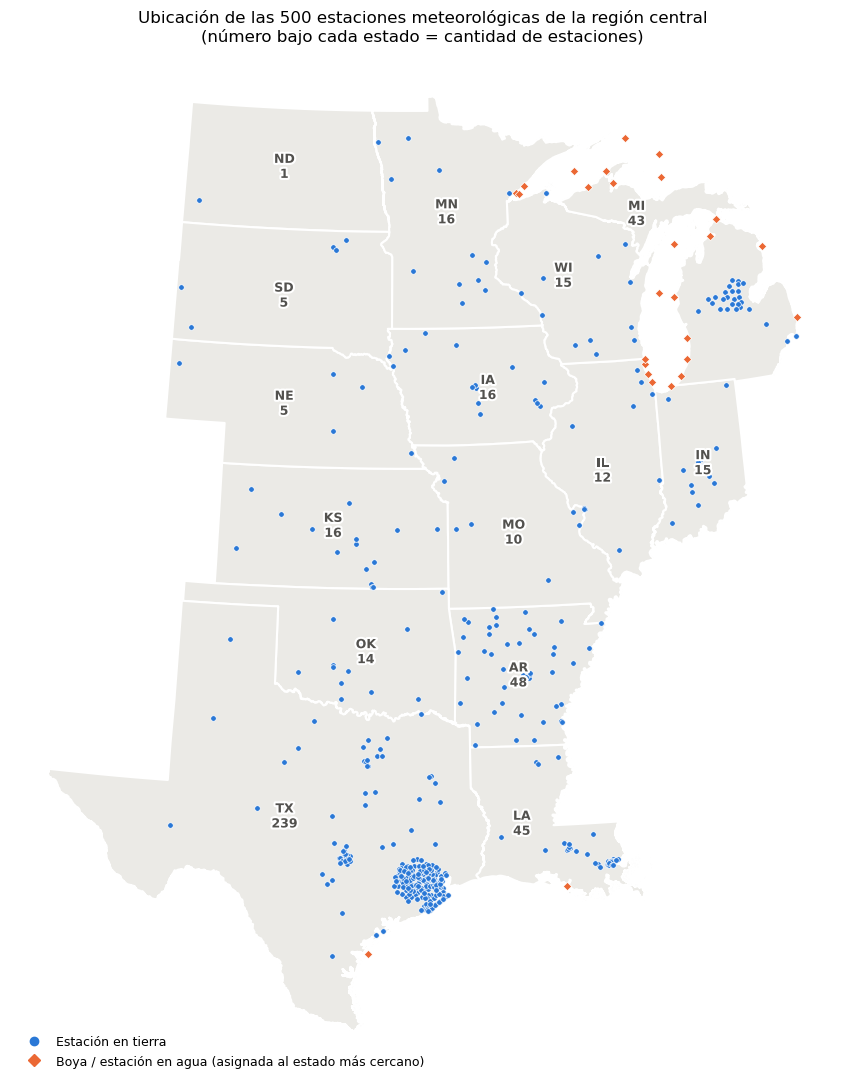

In [10]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe

estados_plot = estados_central.to_crs(CRS_METRICO)
estaciones_plot = estaciones_central.to_crs(CRS_METRICO)
en_agua = estaciones_plot['origen_estado'].eq('estado más cercano (agua)')

AZUL, NARANJA = '#2a78d6', '#eb6834'

fig, ax = plt.subplots(figsize=(10, 11))
estados_plot.plot(ax=ax, color='#ebeae6', edgecolor='white', linewidth=1.5)

estaciones_plot[~en_agua].plot(ax=ax, color=AZUL, markersize=16,
                               edgecolor='white', linewidth=0.5, zorder=3)
estaciones_plot[en_agua].plot(ax=ax, color=NARANJA, marker='D', markersize=18,
                              edgecolor='white', linewidth=0.5, zorder=3)

# Abreviatura y cantidad de estaciones en cada estado
for _, fila in estados_plot.iterrows():
    p = fila.geometry.representative_point()
    n = detalle_estados.loc[fila['estado'], 'estaciones']
    ax.annotate(f"{fila['estado']}\n{n}", (p.x, p.y), ha='center', va='center',
                fontsize=9, color='#52514e', fontweight='bold', zorder=4,
                path_effects=[pe.withStroke(linewidth=3, foreground='white')])

ax.legend(
    handles=[
        Line2D([], [], marker='o', ls='', color=AZUL, markersize=6, label='Estación en tierra'),
        Line2D([], [], marker='D', ls='', color=NARANJA, markersize=6,
               label='Boya / estación en agua (asignada al estado más cercano)'),
    ],
    loc='lower left', frameon=False, fontsize=9
)
ax.set_title(f'Ubicación de las {len(estaciones_plot)} estaciones meteorológicas de la región central\n'
             '(número bajo cada estado = cantidad de estaciones)', fontsize=12, loc='center')
ax.set_axis_off()
plt.tight_layout()
plt.show()

## 5. Guardado de los datos filtrados

In [11]:
import os

PROCESSED = '../data/processed/'
os.makedirs(PROCESSED, exist_ok=True)

estaciones_central.to_file(PROCESSED + 'estaciones_central.geojson', driver='GeoJSON')
estados_central.to_file(PROCESSED + 'estados_central.geojson', driver='GeoJSON')

print(f'Guardadas {len(estaciones_central)} estaciones y {len(estados_central)} estados en {PROCESSED}')

Guardadas 500 estaciones y 15 estados en ../data/processed/


## 6. Exportación del mapa y las tablas para la presentación

In [12]:
OUT = '../data/out/'
os.makedirs(OUT, exist_ok=True)

# Mapa: PNG en alta resolución (se pega directo en PowerPoint)
fig.savefig(OUT + 'mapa_estaciones.png', dpi=300, bbox_inches='tight', facecolor='white')

# Tablas con encabezados listos para presentar
tabla_estados = (
    detalle_estados.reset_index()
    .rename(columns={
        'estado': 'Abrev.', 'nombre_estado': 'Estado', 'estaciones': 'Estaciones',
        'porcentaje': '%', 'area_miles_km2': 'Área (miles km²)',
        'estaciones_cada_10mil_km2': 'Estaciones / 10.000 km²',
    })
)
tabla_estados = pd.concat([
    tabla_estados,
    pd.DataFrame([{'Abrev.': '', 'Estado': 'Total', 'Estaciones': tabla_estados['Estaciones'].sum(),
                   '%': 100.0, 'Área (miles km²)': tabla_estados['Área (miles km²)'].sum().round(1),
                   'Estaciones / 10.000 km²': round(tabla_estados['Estaciones'].sum() / area_km2.sum() * 1e4, 2)}]),
], ignore_index=True)

tabla_reasignadas = (
    estaciones_gdf.loc[sin_estado, ['id', 'nombre', 'estado', 'origen_estado']]
    .assign(dist_km=(cercano['dist_m'] / 1000).round(1))
    .rename(columns={'id': 'ID', 'nombre': 'Nombre', 'estado': 'Estado asignado',
                     'origen_estado': 'Criterio', 'dist_km': 'Distancia (km)'})
    .replace({'Criterio': {'polígono': 'Dentro del polígono',
                           'estado más cercano (agua)': 'Más cercano (en agua)'}})
)


def tabla_a_png(df, archivo, titulo):
    """Dibuja un DataFrame como tabla y la guarda como PNG."""
    alto_fila = 0.3
    fig_t, ax_t = plt.subplots(figsize=(8, alto_fila * (len(df) + 1) + 0.6))
    ax_t.set_axis_off()
    tabla = ax_t.table(
        cellText=df.astype(str).values, colLabels=df.columns,
        loc='upper center', cellLoc='center',
    )
    tabla.auto_set_font_size(False)
    tabla.set_fontsize(10)
    tabla.scale(1, 1.4)
    tabla.auto_set_column_width(list(range(df.shape[1])))
    for (fila, col), celda in tabla.get_celld().items():
        celda.set_edgecolor('#d9d8d4')
        if fila == 0:
            celda.set_facecolor('#2a78d6')
            celda.set_text_props(color='white', fontweight='bold')
        elif fila % 2 == 0:
            celda.set_facecolor('#f4f4f2')
        if fila > 0 and df.iloc[fila - 1, 1] == 'Total':
            celda.set_text_props(fontweight='bold')
    ax_t.set_title(titulo, fontsize=12, loc='left', pad=8)
    fig_t.savefig(archivo, dpi=300, bbox_inches='tight', facecolor='white')
    plt.close(fig_t)


tabla_a_png(tabla_estados, OUT + 'tabla_estaciones_por_estado.png',
            'Estaciones meteorológicas por estado')
tabla_a_png(tabla_reasignadas, OUT + 'tabla_estaciones_reasignadas.png',
            'Estaciones sin estado en los datos originales y estado asignado')

# CSV editables (separador ';' y coma decimal para abrir directo en Excel en español)
for df, nombre in [(tabla_estados, 'tabla_estaciones_por_estado.csv'),
                   (tabla_reasignadas, 'tabla_estaciones_reasignadas.csv')]:
    df.to_csv(OUT + nombre, sep=';', decimal=',', index=False, encoding='utf-8-sig')

sorted(os.listdir(OUT))

['mapa_estaciones.png',
 'tabla_estaciones_por_estado.csv',
 'tabla_estaciones_por_estado.png',
 'tabla_estaciones_reasignadas.csv',
 'tabla_estaciones_reasignadas.png']